Në këtë detyrë do të ndërtojmë një sistem të thjeshtë për identifikimin e klientëve me sjellje të pazakontë në blerje, duke përdorur algoritmin K-Nearest Neighbors (KNN).

Qëllimi është të identifikojmë klientët që kanë karakteristika dukshëm të ndryshme nga shumica e klientëve të tjerë.

Do të përdorim dy karakteristika:

1. Monthly_Purchases – numri i blerjeve që klienti realizon gjatë një muaji.

2. Average_Amount – shuma mesatare e një blerjeje në euro. Do të krijojmë 100 klientë, do t'i normalizojmë të dhënat, do të llogarisim distancën mesatare nga 5 fqinjët më të afërt dhe në fund do t'i vizualizojmë anomalitë.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

Do të gjenerojmë të dhëna për 100 klientë.

Nga këta:

- 95 klientë do të kenë sjellje normale të blerjes.
  
- 5 klientë do të kenë sjellje të pazakontë (anomalitë). Për këtë shembull, ne i krijojmë vetë anomalitë në mënyrë që të mund të kontrollojmë nëse algoritmi arrin t'i identifikojë.

In [2]:
np.random.seed(42)

# Gjenerimi i 95 klienteve me sjellje normale
normal_customers = np.column_stack([
    np.random.normal(8, 2.5, 95),    # Numri i blerjeve mujore
    np.random.normal(60, 15, 95)    # Shuma mesatare e blerjes
])

# Kufizimi i vlerave ne intervale realiste
#np.clip(array, minimum, maximum)
normal_customers[:, 0] = np.clip(normal_customers[:, 0], 1, 16)
normal_customers[:, 1] = np.clip(normal_customers[:, 1], 10, 110)

# Gjenerimi i 5 klienteve me sjellje anomale
anomalies = np.array([
    [30, 250],
    [1, 250],
    [35, 15],
    [40, 300],
    [25, 350]
])

# Bashkimi i te gjitha te dhenave
data = np.vstack([normal_customers, anomalies])

# Krijimi i DataFrame
df = pd.DataFrame(data, columns=[
    'Blerjet mujore',
    'Shuma mesatare'
])

# Identifikuesi i klienteve
df.insert(0, 'Klient_ID', range(1, 101))

# Etiketa vetem per verifikim
df['Shpenzimi_Etiketa'] = ['Normale'] * 95 + ['Anomali'] * 5

df.head()

,Klient_ID,Blerjet mujore,Shuma mesatare,Shpenzimi_Etiketa
0,1,9.241785,38.047276,Normale
1,2,7.654339,64.441804,Normale
2,3,9.619221,63.915829,Normale
3,4,11.807575,60.076702,Normale
4,5,7.414617,56.481193,Normale


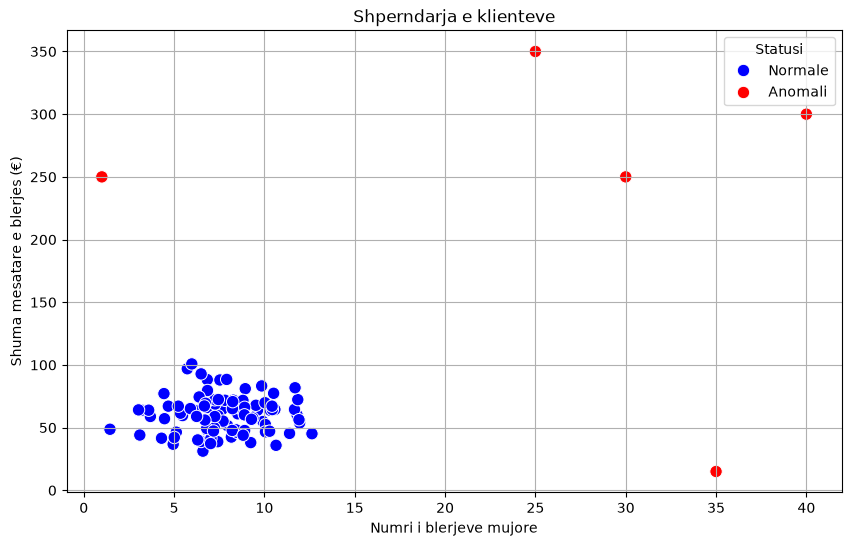

In [3]:
plt.figure(figsize=(10, 6))

#grafiku i shpërndarjes
sns.scatterplot(
    data=df,
    x='Blerjet mujore',
    y='Shuma mesatare',
#përdoret për t'i ndarë observimet në grupe dhe për t'i paraqitur me ngjyra të ndryshme.
    hue='Shpenzimi_Etiketa',
    palette={
        'Normale': 'blue',
        'Anomali': 'red'
    },
    s=80
)

plt.title('Shperndarja e klienteve')
plt.xlabel('Numri i blerjeve mujore')
plt.ylabel('Shuma mesatare e blerjes (€)')
plt.legend(title='Statusi')
plt.grid(True)

plt.show()

Para se të aplikojmë KNN, duhet të normalizojmë të dhënat.

Pse është e nevojshme?

Sepse karakteristikat tona kanë shkallë të ndryshme:

- Numri i blerjeve zakonisht varion nga 1 deri në 40.
- Shuma mesatare e blerjeve mund të variojë nga 10 deri në 350 euro. Nëse nuk i normalizojmë, karakteristika Average_Amount mund të ketë ndikim shumë më të madh në llogaritjen e distancës.
  
Përdorim StandardScaler, i cili transformon të dhënat duke pasur mesataren 0 dhe devijimin standard 1.

In [4]:
# Zgjedhja e karakteristikave
X = df[['Blerjet mujore', 'Shuma mesatare']]

# Krijimi i objektit StandardScaler
scaler = StandardScaler()

# Normalizimi i te dhenave
X_scaled = scaler.fit_transform(X)

# Konvertimi ne DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=['Blerjet mujore_stand', 'Shuma mesatare_stand']
)

X_scaled_df.head()

,Blerjet mujore_stand,Shuma mesatare_stand
0,0.102259,-0.651149
1,-0.186069,-0.097606
2,0.170812,-0.108636
3,0.568282,-0.189150
4,-0.229609,-0.264555


Tani aplikojmë algoritmin K-Nearest Neighbors.

Ideja kryesore është:

Për secilin klient, algoritmi identifikon 5 klientët më të afërt në hapësirën e karakteristikave.

Nëse një klient është shumë larg nga fqinjët e tij, ai mund të konsiderohet anomali.

In [5]:
# Krijimi i modelit KNN
knn = NearestNeighbors(n_neighbors=6, metric='euclidean')

# Trajnimi i modelit
knn.fit(X_scaled)

# Gjetja e distancave dhe indekseve te fqinjeve
distances, indices = knn.kneighbors(X_scaled)

Llogaritja e distancës mesatare nga 5 fqinjët

Llogarisim distancën mesatare për secilin klient.

Për llogaritjen e distancës përdorim distancën Euklidiane, e cila përfaqëson largësinë në vijë të drejtë midis dy pikave.

Për dy konsumatorë me pikat:
$$
A=(x_1,y_1)
$$
dhe 
$$
B=(x_2,y_2)
$$

Formula është:
$$
d(A,B)=\sqrt{(x_1-x_2)^2+(y_1-y_2)^2}
$$

In [6]:
# Largojme distancen zero (vet klientin)
# dhe marrim 5 fqinjet e tjere

mean_distances = distances[:, 1:].mean(axis=1)

# Shtimi i rezultatit ne DataFrame
df['KNN_Distance'] = mean_distances

df[['Klient_ID', 'Blerjet mujore',
    'Shuma mesatare', 'KNN_Distance']].head(10)

,Klient_ID,Blerjet mujore,Shuma mesatare,KNN_Distance
0,1,9.241785,38.047276,0.204854
1,2,7.654339,64.441804,0.124304
2,3,9.619221,63.915829,0.126461
3,4,11.807575,60.076702,0.162567
4,5,7.414617,56.481193,0.090926
5,6,7.414658,38.769439,0.134918
6,7,11.948032,53.690320,0.168875
7,8,9.918587,54.859282,0.128753
8,9,6.826314,47.965841,0.097758
9,10,9.356400,57.580714,0.101441


Formula që përdorim është:
$$
D_i = \frac{1}{k}\sum_{j=1}^{k} d(i,NN_j)
$$

Ku:
- $D_i$ – distanca mesatare e klientit $i$.
- $k=5$ – numri i fqinjëve.
- $d(i,NN_j)$ – distanca ndërmjet klientit dhe fqinjit të tij.
Si interpretohet rezultati?
- Distancë e vogël: klienti ka shumë klientë të ngjashëm afër tij.
- Distancë e madhe: klienti është relativisht i izoluar nga klientët e tjerë.
- Distancë shumë e madhe: klienti mund të jetë anomali.
Për shembull, nëse një klient ka distancë mesatare 0.25, ndërsa një tjetër ka 4.50, klienti i dytë është shumë më larg nga fqinjët e tij.

Vlerat janë në hapësirën e standardizuar, jo në euro apo në numër blerjesh.

Identifikimi i anomalive

Tani duhet të vendosim një prag (threshold) për të identifikuar klientët anormalë.

Në këtë shembull përdorim percentilin e 95-të.

Kjo do të thotë se klientët me distancë mesatare më të madhe se 95% e rezultateve do të klasifikohen si anomali.

In [9]:
# Llogaritja e pragut
threshold = np.percentile(mean_distances, 95)

print("Pragu per identifikimin e anomalive:", threshold)

# Identifikimi i anomalive
df['Predicted_Label'] = np.where(
    df['KNN_Distance'] > threshold,
    'Anomali',
    'Normal'
)

# Shfaqja e klienteve anomale
anomalous_customers = df[
    df['Predicted_Label'] == 'Anomali'
]

anomalous_customers[
    ['Klient_ID', 'Blerjet mujore',
     'Shuma mesatare', 'KNN_Distance']
]

Pragu per identifikimin e anomalive: 0.582513751080546


,Klient_ID,Blerjet mujore,Shuma mesatare,KNN_Distance
95,96,30.0,250.0,3.843393
96,97,1.0,250.0,3.435086
97,98,35.0,15.0,4.262238
98,99,40.0,300.0,4.988202
99,100,25.0,350.0,4.479698


Algoritmi nuk e di paraprakisht se cilët klientë janë normalë dhe cilët anormalë.

Ai vetëm analizon distancat ndërmjet klientëve.

Nëse distanca mesatare e një klienti është më e madhe se pragu i përcaktuar, ai klasifikohet si anomali.

Vërejtje: Percentili i 95-të është një zgjedhje e pragut për këtë ushtrim, jo një rregull universal. Ai synon të identifikojë afërsisht 5% të klientëve me distancat më të mëdha.

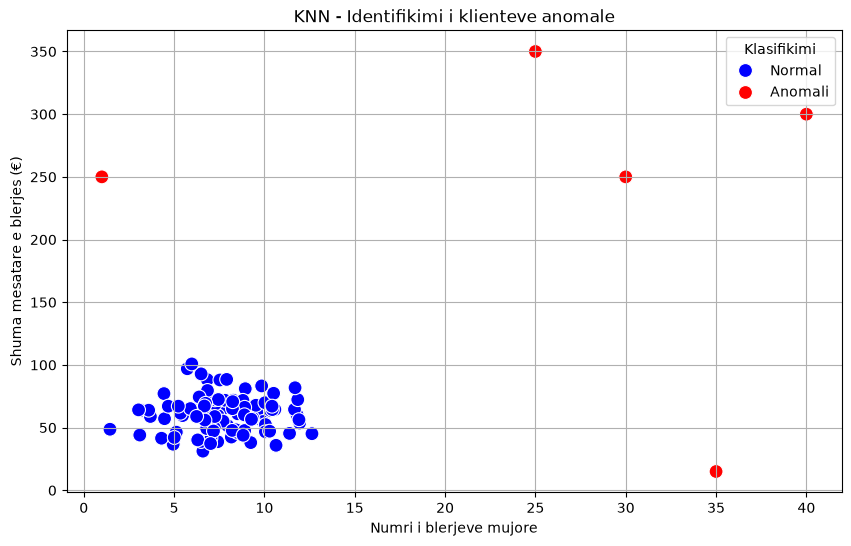

In [10]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Blerjet mujore',
    y='Shuma mesatare',
    hue='Predicted_Label',
    palette={
        'Normal': 'blue',
        'Anomali': 'red'
    },
    s=100
)

plt.title('KNN - Identifikimi i klienteve anomale')
plt.xlabel('Numri i blerjeve mujore')
plt.ylabel('Shuma mesatare e blerjes (€)')

plt.legend(title='Klasifikimi')
plt.grid(True)

plt.show()

In [11]:
# Krahasimi i rezultateve
comparison = pd.crosstab(
    df['Shpenzimi_Etiketa'],
    df['Predicted_Label'],
    rownames=['Actual'],
    colnames=['Predicted']
)

comparison

Predicted,Anomali,Normal
Actual,,
Anomali,5,0
Normale,0,95


In [12]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_true = (df['Shpenzimi_Etiketa'] == 'Anomali').astype(int)

y_pred = (df['Predicted_Label'] == 'Anomali').astype(int)

print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1-Score:", f1_score(y_true, y_pred))

print(classification_report(
    y_true,
    y_pred,
    target_names=['Normal', 'Anomali']
))

Precision: 1.0
Recall: 1.0
F1-Score: 1.0
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00        95
     Anomali       1.00      1.00      1.00         5

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



Ushtrim: Përdorni klasën Manhattan për llogaritjen e distancës për të parë nëse ka dallime!

LOF është algoritëm i bazuar në dendësinë e të dhënave (Density-Based Anomaly Detection).

Ndryshe nga KNN, ku kemi analizuar distancën mesatare të një pike nga fqinjët e saj, LOF analizon dendësinë lokale të një pike në krahasim me dendësinë e fqinjëve të saj.

Ideja kryesore është:
- Nëse një klient ndodhet në një zonë ku ka shumë klientë të tjerë, ai zakonisht konsiderohet normal.

- Nëse një klient ndodhet në një zonë ku ka pak klientë, mund të jetë anomal.

Por LOF shkon një hap më tej: ai krahason dendësinë e një klienti me dendësinë e fqinjëve të tij.

Në këtë detyrë do të përdorim algoritmin Local Outlier Factor (LOF) për të identifikuar pikat anomale në një dataset të gjeneruar me make_blobs nga Scikit-learn.

Vizualizimi fillestar i datasetit

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler


# Gjenerimi i 290 pikave ne tri grupe
X, y = make_blobs(
    n_samples=[120, 100, 70],
    centers=[
        [-5, -5],
        [0, 5],
        [5, -2]
    ],
    #përcakton devijimin standard të pikave rreth qendrës së secilit cluster.
    cluster_std=[0.5, 1.0, 1.5],
    random_state=42
)

# Gjenerimi i 10 pikave anomalike
np.random.seed(42)

anomalies = np.array([
    [-9, 8],
    [-10, -7],
    [8, 8],
    [10, -8],
    [0, -10],
    [9, 5],
    [-8, 2],
    [7, -10],
    [2, 10],
    [-11, -3]
])

# Bashkimi i pikave normale dhe anomale
X = np.vstack([X, anomalies])

# Etiketat reale per verifikim
#1 pikat normale, -1 pikat jonormale
actual_labels = np.array([1] * 290 + [-1] * 10)

print("Numri total i pikave:", X.shape[0])

Numri total i pikave: 300


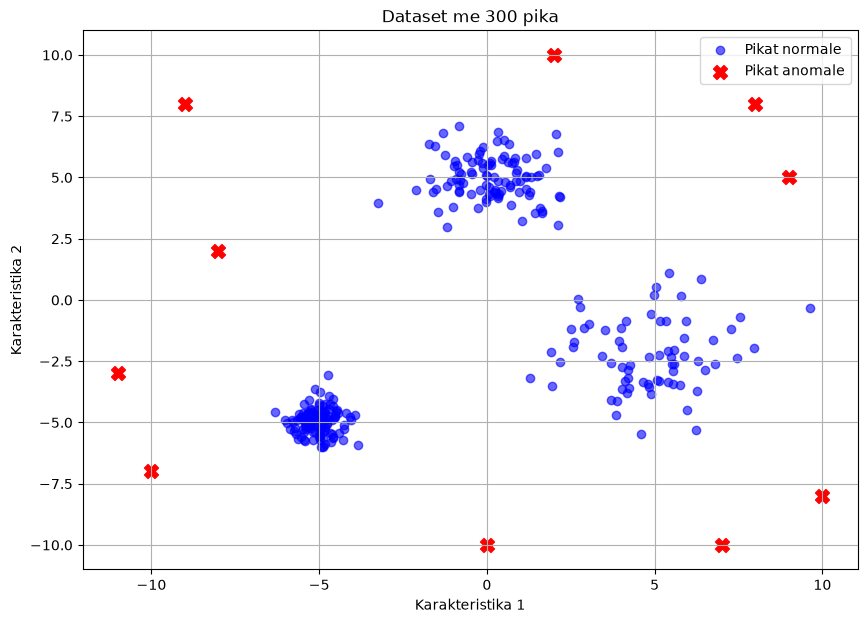

In [15]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X[:290, 0],
    X[:290, 1],
    c='blue',
    label='Pikat normale',
    alpha=0.6
)

plt.scatter(
    X[290:, 0],
    X[290:, 1],
    c='red',
    label='Pikat anomale',
    marker='X',
    s=100
)

plt.title('Dataset me 300 pika')
plt.xlabel('Karakteristika 1')
plt.ylabel('Karakteristika 2')
plt.legend()
plt.grid(True)

plt.show()

Standardizimi i të dhënave 

In [17]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-1.00252055 -0.92015009]
 [ 0.34849061  1.40558429]
 [-0.94549738 -0.85731925]
 [ 0.19670498  1.29497967]
 [ 1.06914316 -0.69443184]]


LOF është një algoritëm që identifikon anomalitë duke krahasuar dendësinë lokale të një pike me dendësinë lokale të fqinjëve të saj.

Për shembull, imagjinoni dy pika:

Pika A ndodhet në një grup ku të gjitha pikat janë afër njëra-tjetrës.
Pika B ndodhet pranë një grupi, por është relativisht më e izoluar nga fqinjët e saj. Edhe nëse pika B nuk është shumë larg nga grupi, dendësia lokale rreth saj mund të jetë më e vogël.
Kjo është arsyeja pse LOF mund të identifikojë anomali që nuk dallohen vetëm duke matur largësinë nga qendra e një grupi.

Funksioni make_blobs() përdoret për të gjeneruar të dhëna artificiale të organizuara në grupe (clusters).

Çdo grup përmban pika që ndodhen relativisht afër njëra-tjetrës.

Janë krijuar tri grupe me dendësi të ndryshme dhe janë shtuar 10 pika të shpërndara jashtë tyre.

In [18]:
lof_10 = LocalOutlierFactor(
    n_neighbors=10,
    contamination=10/300
)

labels_10 = lof_10.fit_predict(X_scaled)

df_10 = pd.DataFrame({
    'X1': X[:, 0],
    'X2': X[:, 1],
    'Actual_Label': actual_labels,
    'Predicted_Label': labels_10,
    'LOF_Score': -lof_10.negative_outlier_factor_
})

print(df_10['Predicted_Label'].value_counts())

Predicted_Label
 1    290
-1     10
Name: count, dtype: int64


Gjenerimi i rezultateve të parashikimit për vlera të ndryshme të fqinjve

In [19]:
from sklearn.neighbors import LocalOutlierFactor
import pandas as pd
import numpy as np

# Vlerat e ndryshme të numrit të fqinjëve
neighbors_values = [5, 10, 15, 20, 30, 50]

# Lista për ruajtjen e rezultateve
comparison = []

# Ruajtja e etiketave për secilin konfigurim
predictions_dict = {}

for k in neighbors_values:

    lof = LocalOutlierFactor(
        n_neighbors=k,
        contamination=10/300
    )

    # Ekzekutimi i LOF
    predictions = lof.fit_predict(X_scaled)

    # Ruajtja e rezultateve
    predictions_dict[k] = predictions

    # Numërimi i pikave normale dhe anomale
    normal_count = np.sum(predictions == 1)
    anomaly_count = np.sum(predictions == -1)

    comparison.append({
        'N_Neighbors': k,
        'Normal_Points': normal_count,
        'Anomalies': anomaly_count
    })

# Krijimi i tabelës krahasuese
comparison_df = pd.DataFrame(comparison)

display(comparison_df)

,N_Neighbors,Normal_Points,Anomalies
0,5,290,10
1,10,290,10
2,15,290,10
3,20,290,10
4,30,290,10
5,50,290,10


In [20]:
import numpy as np
a=np.random.normal(8, 2.5, 95)
b=np.random.normal(60, 15, 95)
c=np.column_stack([
    a,
    b
])
print(c)

[[  9.24178538  38.04727578]
 [  7.65433925  64.44180416]
 [  9.61922135  63.91582908]
 [ 11.80757464  60.07670185]
 [  7.41461656  56.481193  ]
 [  7.41465761  38.76943887]
 [ 11.94803204  53.69032016]
 [  9.91858682  54.85928225]
 [  6.82631404  47.96584096]
 [  9.35640011  57.58071433]
 [  6.84145577  66.06076285]
 [  6.83567562  88.29278852]
 [  8.60490568  62.61866719]
 [  3.21679939  63.86325586]
 [  3.68770542  58.88331126]
 [  6.59428118  31.21843177]
 [  5.4679222   59.60229187]
 [  8.78561833  60.90345315]
 [  5.72993981  96.94863169]
 [  4.46924075  57.11458553]
 [ 11.66412192  64.52321014]
 [  7.43555925  59.47932345]
 [  8.16882051  42.46982944]
 [  4.43812953  77.14234222]
 [  6.63904319  71.27899549]
 [  8.27730647  71.86547921]
 [  5.12251606  46.35918818]
 [  8.93924505  81.04191466]
 [  6.49840328  38.97223406]
 [  7.27076563  68.80285641]
 [  6.49573347  92.85683439]
 [ 12.63069546  45.14195512]
 [  7.96625694  51.50553406]
 [  5.35572268  61.49477048]
 [ 10.05636228

In [21]:
values = np.array([-5, 3, 8, 20, 150])

result = np.clip(values, 1, 10)

print(result)

[ 1  3  8 10 10]


Precision na tregon se nga të gjithë klientët që algoritmi i ka klasifikuar si anomalë, sa prej tyre janë vërtet anomalë.

Formula:
$$
Precision = \frac{TP}{TP+FP}
$$

Recall na tregon se nga të gjithë klientët që janë realisht anomalë, sa prej tyre algoritmi ka arritur t'i identifikojë.

Formula:
$$
Recall = \frac{TP}{TP+FN}
$$

F1-score është mesatarja harmonike e Precision dhe Recall. Përdoret për të vlerësuar balancën ndërmjet këtyre dy metrikave.

Formula:
$$
F1 = 2 \times \frac{Precision \times Recall}
{Precision + Recall}
$$

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

from scipy.spatial.distance import cdist

Fillimisht krijojmë 300 pika normale, të shpërndara në tri grupe (clusters). Pastaj shtojmë katër pika ekstreme, të cilat do t'i trajtojmë si anomali të njohura.

In [26]:
X, _ = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=0.7,
    random_state=42
)

# Shtimi i anomalive
outliers = np.array([
    [10, 10],
    [-10, -10],
    [12, -8],
    [-8, 10]
])

# Bashkimi i pikave normale me anomalitë
X = np.vstack([X, outliers])

print("Dataset shape:", X.shape)
print("Number of observations:", len(X))

Dataset shape: (304, 2)
Number of observations: 304


Aplikimi i K-means duke përcaktuar numrin e cluster-ave në 3.

K-Means është një algoritëm i Machine Learning që përdoret për të grupuar të dhënat në disa grupe (clusters), bazuar në ngjashmërinë ndërmjet tyre.

Është një algoritëm i kategorisë Unsupervised Learning, që do të thotë se mund të identifikojë grupe në të dhëna pa pasur nevojë për etiketa paraprake.

Ideja kryesore është që:
- Pikat që janë të ngjashme me njëra-tjetrën të vendosen në të njëjtin cluster.
- Pikat që janë të ndryshme të vendosen në cluster-a të ndryshëm.
- Çdo cluster të ketë një qendër të quajtur Centroid.

In [27]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Trajnimi i modelit
kmeans.fit(X)

# Etiketat e cluster-ave
labels = kmeans.labels_

# Centroid-et
centroids = kmeans.cluster_centers_

print("Centroids:")
print(centroids)

Centroids:
[[-2.64952689  9.04434127]
 [-6.91346377 -6.98299186]
 [ 4.83817256  1.97977147]]


Python(38753) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Parametri n_clusters=3 përcakton që algoritmi duhet t'i ndajë të dhënat në tri grupe.

Pas trajnimit:
- kmeans.labels_ përmban cluster-in e secilës pikë.
- kmeans.cluster_centers_ përmban koordinatat e centroid-eve.
- kmeans.inertia_ përmban shumën e katrorëve të distancave të pikave nga centroid-et përkatëse.
  
Centroid-i përfaqëson qendrën mesatare të pikave që i përkasin një cluster-i.

Çdo pikë i caktohet centroid-it më të afërt nga algoritmi K-Means.

In [28]:
distances = cdist(X, centroids, metric='euclidean')

# Indeksi i centroid-it më të afërt
nearest_centroid = np.argmin(distances, axis=1)

print("First 10 nearest centroid assignments:")
print(nearest_centroid[:10])

First 10 nearest centroid assignments:
[1 1 0 2 1 2 0 2 0 0]


In [29]:
np.argmin(distances, axis=1)

array([1, 1, 0, 2, 1, 2, 0, 2, 0, 0, 0, 2, 0, 0, 1, 0, 1, 2, 0, 0, 0, 0,
       2, 1, 0, 1, 1, 2, 2, 0, 0, 0, 1, 0, 1, 0, 1, 2, 1, 2, 2, 0, 1, 2,
       0, 0, 1, 2, 1, 2, 2, 1, 1, 0, 1, 2, 1, 0, 2, 0, 1, 2, 2, 1, 1, 2,
       2, 1, 1, 0, 2, 1, 1, 0, 0, 1, 1, 2, 0, 2, 0, 0, 1, 0, 2, 1, 1, 0,
       2, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 2, 0, 2, 0, 0, 0, 0, 0, 2, 1,
       2, 0, 0, 0, 0, 2, 1, 2, 1, 2, 2, 2, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 2, 2, 1, 0, 1, 0, 0, 1, 0, 2, 2, 2, 0, 2, 0, 0, 1, 2, 1,
       0, 2, 2, 1, 1, 0, 0, 1, 1, 1, 0, 1, 2, 0, 0, 0, 0, 0, 2, 0, 2, 2,
       2, 0, 2, 2, 1, 0, 1, 2, 2, 1, 2, 0, 2, 2, 1, 1, 2, 1, 2, 2, 2, 2,
       0, 1, 0, 0, 2, 2, 0, 2, 1, 1, 2, 0, 0, 1, 2, 2, 1, 1, 1, 1, 0, 1,
       1, 2, 1, 1, 0, 2, 1, 1, 2, 0, 0, 1, 0, 1, 2, 2, 1, 2, 1, 1, 1, 2,
       2, 0, 1, 2, 2, 2, 1, 2, 1, 2, 1, 2, 2, 1, 2, 0, 1, 0, 0, 0, 1, 0,
       2, 2, 1, 2, 2, 0, 0, 2, 2, 2, 1, 1, 1, 0, 0, 0, 2, 2, 2, 2, 1, 2,
       1, 2, 2, 1, 0, 2, 2, 0, 1, 0, 2, 0, 1, 1, 2,

In [30]:
# Distanca minimale për secilën pikë
min_distances = np.min(distances, axis=1)

# Krijimi i DataFrame
results = pd.DataFrame({
    'Feature_1': X[:, 0],
    'Feature_2': X[:, 1],
    'Cluster': labels,
    'Nearest_Centroid': nearest_centroid,
    'Distance': min_distances
})

results.head(10)

,Feature_1,Feature_2,Cluster,Nearest_Centroid,Distance
0,-7.201180,-7.475001,1,1,0.569959
1,-7.481917,-7.149298,1,1,0.592281
2,-1.933416,8.159696,0,0,1.138162
3,4.487502,2.742313,2,2,0.839309
4,-8.306314,-7.585770,1,1,1.517687
5,5.240241,1.861213,2,2,0.419184
6,-2.387971,9.284008,0,0,0.354756
7,4.928931,1.578562,2,2,0.411346
8,-2.844620,8.884325,0,0,0.252322
9,-3.343110,9.473874,0,0,0.815816


Tani përcaktojmë pragun (threshold) për identifikimin e anomalive.

Përdorim percentilin 95 të distancave.

In [31]:
# Llogaritja e pragut
threshold = np.percentile(min_distances, 95)

print("Anomaly threshold:", threshold)

# Identifikimi i anomalive
results['Anomaly'] = results['Distance'] > threshold

# Numri i anomalive
print("Detected anomalies:", results['Anomaly'].sum())

# Shfaqja e pikave anomale
detected_anomalies = results[results['Anomaly'] == True]

detected_anomalies

Anomaly threshold: 1.7032623517118577
Detected anomalies: 16


,Feature_1,Feature_2,Cluster,Nearest_Centroid,Distance,Anomaly
55,5.000412,4.670082,2,2,2.695198,True
61,6.133002,0.606708,2,2,1.887296,True
63,-4.724411,-6.096407,1,1,2.361776,True
142,-5.437104,-5.651371,1,1,1.988178,True
160,-4.343019,9.589618,0,0,1.779113,True
167,-2.467036,10.738556,0,0,1.704014,True
177,-2.694457,10.918405,0,0,1.874602,True
185,-8.609778,-7.437936,1,1,1.756262,True
188,2.370992,1.256098,2,2,2.571125,True
216,-6.436680,-5.290625,1,1,1.758246,True


Vizualizimi 

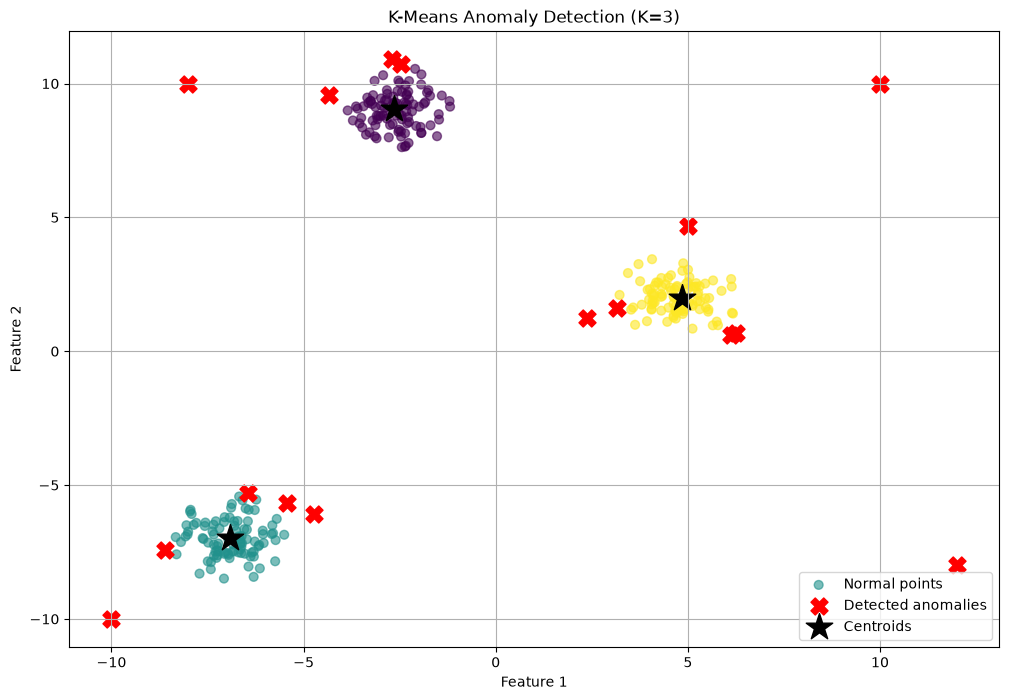

In [32]:
plt.figure(figsize=(12, 8))

# Pikat normale
normal_points = results[results['Anomaly'] == False]

plt.scatter(
    normal_points['Feature_1'],
    normal_points['Feature_2'],
    c=normal_points['Cluster'],
    cmap='viridis',
    s=40,
    alpha=0.6,
    label='Normal points'
)

# Pikat anomale
anomaly_points = results[results['Anomaly'] == True]

plt.scatter(
    anomaly_points['Feature_1'],
    anomaly_points['Feature_2'],
    color='red',
    marker='X',
    s=150,
    label='Detected anomalies'
)

# Centroid-et
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color='black',
    marker='*',
    s=400,
    label='Centroids'
)

plt.title('K-Means Anomaly Detection (K=3)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

plt.legend()
plt.grid(True)
plt.show()

Pikat që janë shumë larg centroid-eve kanë probabilitet më të madh të konsiderohen anomali nga kjo metodë.

Analizimi se si ndryshon identifikimi i anomalive kur ndryshojmë numrin e cluster-ave.

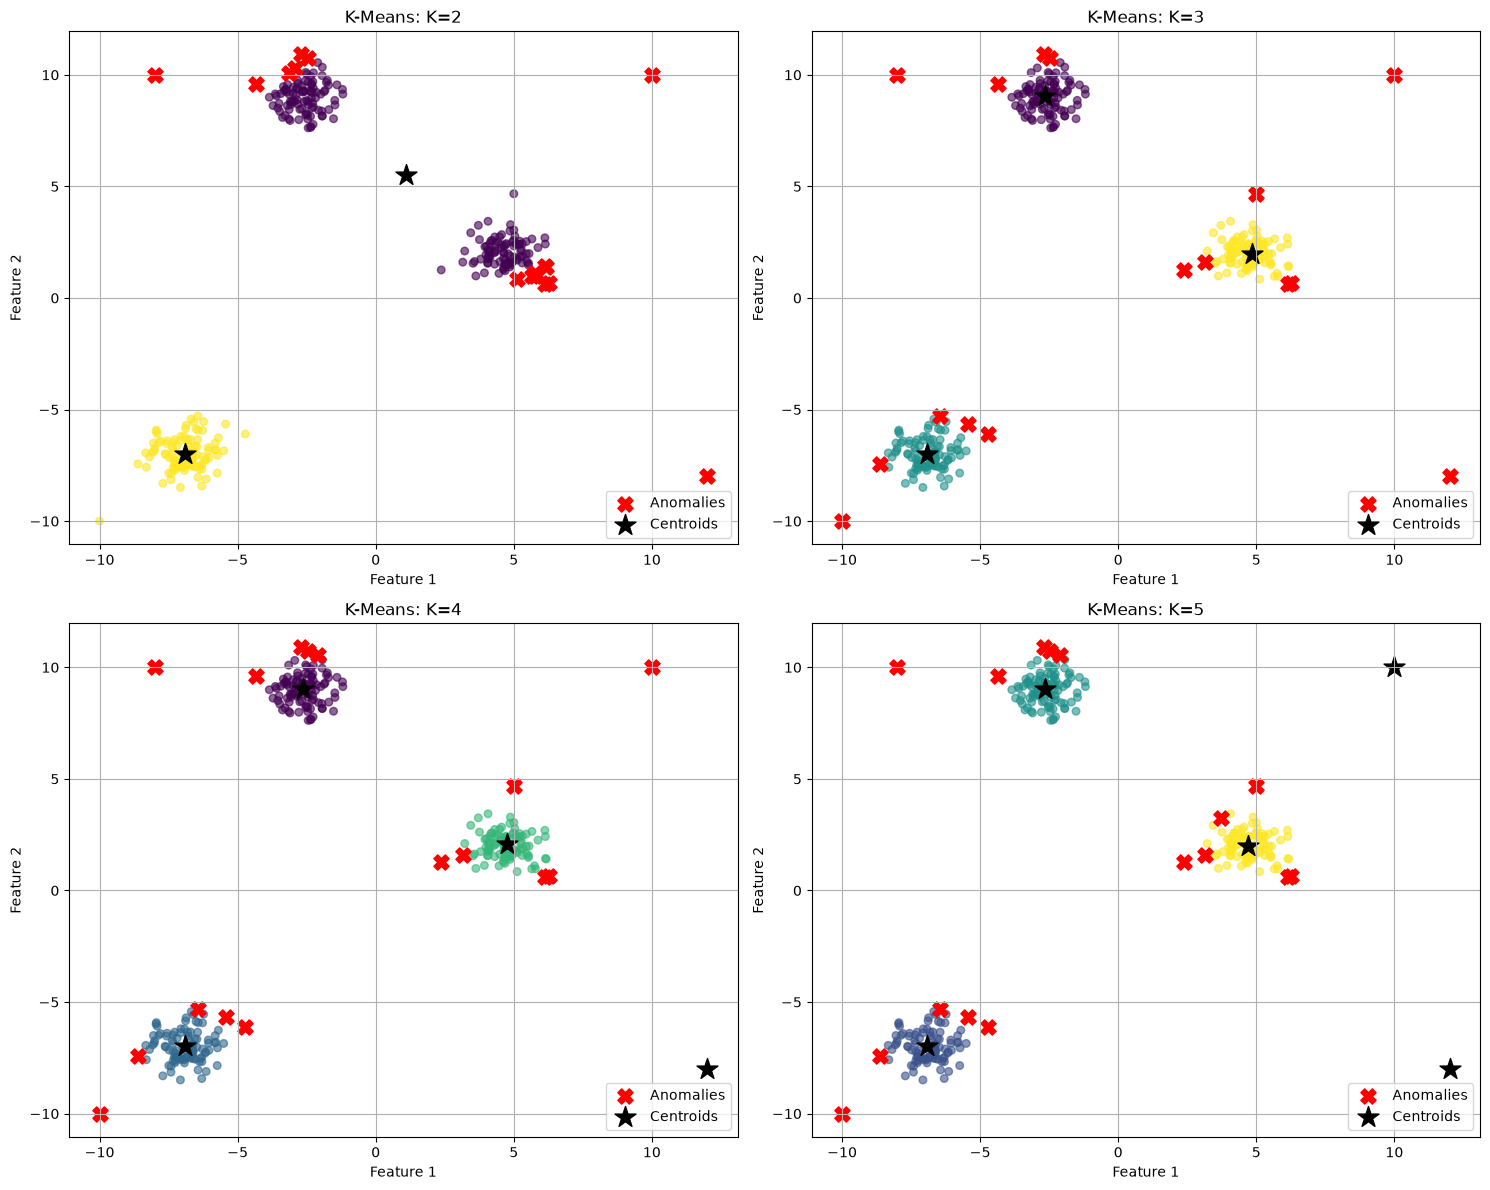

In [33]:
k_values = [2, 3, 4, 5]

comparison_results = []

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

for i, k in enumerate(k_values):

    # K-Means
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    centroids = kmeans.cluster_centers_

    # Distanca nga centroid-i më i afërt
    distances = cdist(X, centroids)

    min_distances = distances.min(axis=1)

    # Threshold - Percentili 95
    threshold = np.percentile(min_distances, 95)

    # Identifikimi i anomalive
    anomalies = min_distances > threshold

    # Ruajtja e rezultateve
    comparison_results.append({
        'K': k,
        'Threshold': threshold,
        'Detected Anomalies': anomalies.sum(),
        'Inertia': kmeans.inertia_
    })

    # Vizualizimi
    ax = axes[i // 2, i % 2]

    ax.scatter(
        X[~anomalies, 0],
        X[~anomalies, 1],
        c=labels[~anomalies],
        cmap='viridis',
        s=30,
        alpha=0.6
    )

    ax.scatter(
        X[anomalies, 0],
        X[anomalies, 1],
        color='red',
        marker='X',
        s=120,
        label='Anomalies'
    )

    ax.scatter(
        centroids[:, 0],
        centroids[:, 1],
        color='black',
        marker='*',
        s=250,
        label='Centroids'
    )

    ax.set_title(f'K-Means: K={k}')
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [34]:
comparison_df = pd.DataFrame(comparison_results)

comparison_df

,K,Threshold,Detected Anomalies,Inertia
0,2,6.129368,16,5947.865347
1,3,1.703262,16,569.826031
2,4,1.599881,16,417.444483
3,5,1.599881,16,326.412769


K: numri i cluster-ave.



Threshold: pragu i distancës për identifikimin e anomalive.



Detected Anomalies: numri i pikave të identifikuara si anomali.



Inertia: shuma e katrorëve të distancave të pikave nga centroid-et përkatëse.

In [36]:
# Indekset e katër anomalive të shtuara
actual_outlier_indices = np.arange(300, 304)

detailed_results = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    distances = cdist(X, kmeans.cluster_centers_)

    min_distances = distances.min(axis=1)

    threshold = np.percentile(min_distances, 95)

    detected = min_distances > threshold

    detected_actual = detected[actual_outlier_indices].sum()

    detailed_results.append({
        'K': k,
        'Total detected': detected.sum(),
        'Actual outliers detected': detected_actual,
        'Actual outliers missed': 4 - detected_actual
    })

pd.DataFrame(detailed_results)

,K,Total detected,Actual outliers detected,Actual outliers missed
0,2,16,3,1
1,3,16,4,0
2,4,16,3,1
3,5,16,2,2
